# 13 — Telco: Why this prediction, and how do we explain the decision?
**Session 7 · Objective:** Explain two individual churn predictions, aggregate their
SHAP contributions into a global view, and choose an explanation that the audience
can use. This continues the Session 7 v3 order after notebook 12's global importance.

Keep three questions separate: **what information does the model use across customers?**
**Why this probability for this customer?** **Why this action?** The last also needs
the business policy and any human review. A risk model does not tell us which offer
would persuade someone to stay.

In [1]:
# Locate the course CSV with paths that work across operating systems.
from pathlib import Path
# Fingerprint the source bytes so comparisons use the classroom dataset.
import hashlib
# Report the Python version alongside the numerical evidence.
import platform
# Work with arrays, logarithms and reproducible random permutations.
import numpy as np
# Keep customer fields, indices and result tables labelled.
import pandas as pd
# Build figures with explicit axes, titles and measurement units.
import matplotlib.pyplot as plt
# Report the installed scikit-learn version instead of assuming a class match.
import sklearn
# Reuse the course tree model and its built-in gain and TreeSHAP calculations.
import xgboost as xgb
# Display several readable tables from a single notebook cell.
from IPython.display import display
# Convert a complete log-odds score back to a probability with the logistic function.
from scipy.special import expit
# Route measured quantities and categories through separate preparation branches.
from sklearn.compose import ColumnTransformer
# Learn missing-value replacements from fitting customers only.
from sklearn.impute import SimpleImputer
# Measure performance loss after shuffling inputs to an already fitted model.
from sklearn.inspection import permutation_importance
# Keep the Logistic Regression algorithm selected in Session 6.
from sklearn.linear_model import LogisticRegression
# Evaluate ranking with AP and numerical probability error with Brier.
from sklearn.metrics import average_precision_score, brier_score_loss
# Recreate the stratified fitting, validation and holdout boundaries.
from sklearn.model_selection import train_test_split
# Fit preparation and prediction within a single training boundary.
from sklearn.pipeline import Pipeline
# Scale numeric inputs, encode categories and wrap the row-wise log formulas.
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer

In [2]:
# Print the actual environment alongside the saved numerical evidence.
print({"Python": platform.python_version(), "NumPy": np.__version__,
       "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
       "XGBoost": xgb.__version__})
# Use readable figures and remove borders that do not help explain the result.
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False,
                     "axes.spines.right": False})
# Display four decimals in tables without rounding the underlying calculations.
pd.options.display.float_format = '{:,.4f}'.format

{'Python': '3.12.9', 'NumPy': '2.5.3', 'pandas': '3.0.6', 'scikit-learn': '1.9.1', 'XGBoost': '3.4.1'}


## Rebuild the Session 6 experiment
Keep the selected model and ask a new question. Session 6 retained raw Logistic
Regression probabilities with two logs; neither calibration method improved validation
Brier. Its offer policy used risk at least 0.20, with uncertain incremental advantage
and an experimental pilot still needed.

We reproduce the same dataset hash, 20% stratified holdout (seed 42), and development
split into 3,943 fitting and 1,691 validation customers (seed 606). Fit only on fitting;
explain validation without refitting. The 1,409 holdout customers are not used here.
They were already inspected in Session 6 classroom evidence, so this is no fresh
untouched evaluation. Validation has also informed earlier choices: treat these
explanations as classroom diagnostics, not independent model-selection evidence.

This notebook runs independently from `notebooks/` with the root course requirements.
All population statistics stay inside the Pipeline. Numeric parsing and row-wise logs
learn nothing from other customers. `SeniorCitizen` remains categorical.

In [3]:
# Point from notebooks/ to the CSV committed with this repository.
data_path = Path('../data/telco.csv')
# Fingerprint the file before cleaning so byte-for-byte identity can be checked.
fingerprint = hashlib.sha256(data_path.read_bytes()).hexdigest()
# This reference identifies the dataset; it is not a fitted result.
class_fingerprint = '88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a'
# Stop if the dataset changed instead of silently comparing incompatible figures.
assert fingerprint == class_fingerprint, 'Dataset differs from class; investigate first.'
# Keep the verified fingerprint visible in the saved output.
print('Dataset SHA-256:', fingerprint)
# Load one row per customer.
df = pd.read_csv(data_path)
# Confirm the expected size and that customers have not been duplicated.
assert df.shape == (7043, 21) and df.customerID.is_unique
# Parse each charge independently; the eleven blank strings become missing values.
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
# Exclude both the answer and the identifier from the model inputs.
X = df.drop(columns=['Churn', 'customerID'])
# Encode observed churn as 1 and staying as 0.
y = df['Churn'].eq('Yes').astype(int)

Dataset SHA-256: 88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a


In [4]:
# Reserve the same 20% holdout as notebook 03 before fitting any transformation.
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=.20, stratify=y, random_state=42
)
# Use validation to choose corrections and cutoffs; keep fitting customers separate.
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_dev, y_dev, test_size=.30, stratify=y_dev, random_state=606
)
# Check the four sample sizes from the classroom protocol.
assert (len(X_dev), len(X_test), len(X_fit), len(X_valid)) == (5634, 1409, 3943, 1691)
# Check that fitting and validation do not share customers.
assert set(X_fit.index).isdisjoint(X_valid.index)
# Check that the holdout stays outside all development decisions.
assert set(X_dev.index).isdisjoint(X_test.index)
# Check that the inner split accounts for every development customer exactly once.
assert set(X_fit.index) | set(X_valid.index) == set(X_dev.index)
# Check input/outcome order at each boundary before converting anything to arrays.
for features, labels in [(X_fit, y_fit), (X_valid, y_valid), (X_test, y_test)]:
    # Equal indices mean row i describes the same customer on both sides.
    assert features.index.equals(labels.index)
# Display actual sample sizes; these are not extrapolated campaign counts.
display(pd.Series({'Development n': len(X_dev), 'Holdout n': len(X_test),
                   'Fitting n': len(X_fit), 'Validation n': len(X_valid)}))

Development n    5634
Holdout n        1409
Fitting n        3943
Validation n     1691
dtype: int64

## Hold the algorithm fixed; change two inputs
The first model uses original inputs. The finalist retains them and adds `log1p(tenure)` and `log1p(TotalCharges)`. These row-wise logs express diminishing changes and learn no population statistics. This is **not** notebook 07's Logistic +logs versus XGBoost +polynomials comparison. `SeniorCitizen` is categorical despite its 0/1 storage.

In [5]:
# Name the measured quantities explicitly; SeniorCitizen is a category, not a measurement.
NUMERIC = ['tenure', 'MonthlyCharges', 'TotalCharges']
# Collect all remaining original inputs as categorical columns.
CATEGORICAL = []
# Inspect each original column rather than inferring its role from its storage type.
for column in X.columns:
    # Anything outside the three measured quantities is one-hot encoded.
    if column not in NUMERIC:
        # Retain column order so the transformed model inputs stay reproducible.
        CATEGORICAL.append(column)
# Make the course's treatment of the stored 0/1 field explicit.
assert 'SeniorCitizen' in CATEGORICAL

# Define only the row-wise formula; it learns no statistics from other customers.
def add_logs(frame):
    # Copy inputs so another candidate can still use the original columns unchanged.
    result = frame.copy()
    # Compress tenure changes while allowing tenure zero: log1p(x) means log(1 + x).
    result['log_tenure'] = np.log1p(result['tenure'])
    # Missing total charges remain missing until the training imputer handles them.
    result['log_total'] = np.log1p(result['TotalCharges'])
    # Return originals plus the two added inputs.
    return result

In [6]:
# Rebuild an unfitted Pipeline each time so candidates do not share learned statistics.
def build_model(logs=False):
    # Begin with the original three measured quantities.
    numeric_columns = list(NUMERIC)
    # The baseline passes original inputs straight through.
    feature_step = 'passthrough'
    # Add logs only for the augmented candidate, retaining the original inputs.
    if logs:
        # Route the two derived numeric columns through the numeric branch too.
        numeric_columns.extend(['log_tenure', 'log_total'])
        # Adapt the simple row-wise function to the Pipeline's fit/transform interface.
        feature_step = FunctionTransformer(add_logs)
    # Learn numeric replacements and scales inside each training partition.
    numeric_preprocessing = Pipeline([
        ('impute', SimpleImputer(strategy='median')),  # Training medians replace missing values.
        ('scale', StandardScaler())  # Training means and standard deviations set the scale.
    ])
    # Keep categorical encoding separate from measured quantities.
    preprocessing = ColumnTransformer([
        ('num', numeric_preprocessing, numeric_columns),
        ('cat', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL)
    ])
    # Keep the regularization and optimizer identical for the two candidates.
    classifier = LogisticRegression(C=1, solver='lbfgs', max_iter=2000)
    # Fit the feature step, preprocessing and classifier within the same boundary.
    return Pipeline([('features', feature_step), ('preprocess', preprocessing),
                     ('model', classifier)])

In [7]:
# Keep Session 6's selected recipe; do not fit on customers being explained.
finalist = build_model(logs=True).fit(X_fit, y_fit)
# Keep churn probabilities aligned with validation rows; column 1 is the churn class.
probabilities = finalist.predict_proba(X_valid)[:, 1]
# Save the unshuffled AP as the common reference for importance calculations.
baseline_ap = average_precision_score(y_valid, probabilities)
# Show ranking performance before explaining what information the model uses.
print(f"Validation AP: {baseline_ap:.6f}")
# Report probability error separately so ranking and probability quality are not confused.
print(f"Validation Brier: {brier_score_loss(y_valid, probabilities):.6f}")

Validation AP: 0.675675
Validation Brier: 0.129578


## Start from a reference, then share credit
**Question:** How did one prediction differ from a chosen reference?
A hypothetical home starts at EUR 250k: near the station adds 45k, small floor area
subtracts 25k, renovation adds 10k, giving EUR 280k. The numbers explain a prediction;
they do not establish what a renovation would cause in a real sale.

When signals overlap, order changes credit. In the lesson's second example, area alone
adds 30k, rooms alone adds 25k, and both add 40k. SHAP averages marginal contributions
over possible feature orderings. With two features we can calculate every order.

In [8]:
# A small cooperative game in EUR thousands, not evidence about Telco customers.
orders = pd.DataFrame({'Area': [30, 40-25], 'Rooms': [40-30, 25]},
                       index=['Area first', 'Rooms first'])
# Inspect how the same total increase is allocated under each feature ordering.
display(orders)
# Introduce the step that removes dependence on which feature was added first.
print('Average over both orders:')
# Average each feature's marginal contributions over the two possible orders.
display(orders.mean())
# Check that averaging credit still reconstructs the full 40k increase.
assert orders.mean().sum() == 40

,Area,Rooms
Area first,30,10
Rooms first,15,25


Average over both orders:


Area    22.5000
Rooms   17.5000
dtype: float64

Both orders add to 40k; averaging gives area 22.5k and rooms 17.5k. With many features
we need efficient methods. Crucially, the meaning of a **missing feature** depends on
the background data and how the explainer handles dependencies. SHAP does not supply
a unique causal explanation independent of those choices.

## Read the scale before reading a contribution
The lesson's illustrative probability arithmetic is `30% + 18 pp − 8 pp + 10 pp = 50%`.
Our actual Logistic Regression instead adds contributions in **log odds**:
`log(p / (1-p))`. Convert the **total** back to probability with the logistic function
`expit(score) = 1 / (1 + exp(-score))`.

In [9]:
# Choose risks below, at and above 50% to show why log odds can be negative or positive.
example_probabilities = np.array([.20, .50, .80])
# Place probabilities, odds and natural log odds side by side on their different scales.
display(pd.DataFrame({
    'Probability': example_probabilities,
    # Odds compare the chance of leaving with the chance of staying.
    'Odds': example_probabilities / (1-example_probabilities),
    # Taking the natural logarithm makes equal leave/stay odds correspond to zero.
    'Log odds': np.log(example_probabilities / (1-example_probabilities))
}))

,Probability,Odds,Log odds
0,0.2000,0.2500,-1.3863
1,0.5000,1.0000,0.0000
2,0.8000,4.0000,1.3863


Negative log odds mean risk below 50%, not a negative probability. A positive
contribution raises risk relative to the reference; its magnitude here is **not**
percentage points. Applying `expit` to each contribution separately would not give
pieces of probability that sum to the prediction.

## Linear SHAP for the selected Telco model
**Question:** Which inputs pushed this customer's fitted score above or below the
reference score? We use the same exact additive calculation as the v3 class script.

For transformed column `j`, `phi_j = beta_j × (z_j − mean_fit(z_j))`.
The base is `intercept + beta @ mean_fit(z)`. This is interventional linear SHAP on
the **log-odds score**, using the empirical fitting distribution as background. It
does not account for feature correlations as a conditional explainer would.
We sum each raw input's one-hot columns or original-plus-log terms into one group.
For this additive score that preserves the complete prediction and matches the
classroom raw-feature grouping. We expose the formula instead of adding another
library; see [LinearExplainer's documented formula](https://shap.readthedocs.io/en/stable/generated/shap.LinearExplainer.html).

In [10]:
# Track each encoded column back to the raw field that generated it.
def encoded_groups(pipeline):
    # Inspect the fitted transformer so the mapping follows its actual output order.
    preprocessing = pipeline.named_steps['preprocess']
    # Read numeric field names from the first branch; these appear first in the encoded matrix.
    numeric = preprocessing.transformers_[0][2]
    # Read the raw categorical names in the second branch's fitted order.
    categorical = preprocessing.transformers_[1][2]
    # Recover learned category levels to count each field's one-hot columns.
    encoder = preprocessing.named_transformers_['cat']
    # Build one raw-feature label for every column received by the classifier.
    labels = []
    # Map numeric outputs in order, including any added logarithms.
    for name in numeric:
        # Treat tenure and its deterministic log as one source of information.
        if name == 'log_tenure':
            # Assign the log term to the original tenure field for grouped explanations.
            name = 'tenure'
        # Apply the same grouping rule to the log of accumulated charges.
        elif name == 'log_total':
            # Assign the derived term to the raw billing field that generated it.
            name = 'TotalCharges'
        # Append the source label in exactly the same position as its transformed column.
        labels.append(name)
    # Pair each categorical input with the levels learned for that input.
    for name, levels in zip(categorical, encoder.categories_):
        # The default encoder emits one column for each learned level.
        for level in levels:
            # Append the source label in exactly the same position as its transformed column.
            labels.append(name)
    # Return an array so a Boolean mask can select all columns belonging to one raw field.
    return np.array(labels)

In [11]:
# Average transformed fitting rows, never the validation population being explained.
background = np.asarray(finalist[:-1].transform(X_fit).mean(axis=0)).ravel()
# Transform validation customers with fitted preparation, excluding the classifier itself.
observed = finalist[:-1].transform(X_valid)
# One-hot preparation can return a sparse matrix rather than an ordinary array.
if hasattr(observed, 'toarray'):
    # Make element-wise subtraction explicit; this small classroom matrix fits in memory.
    observed = observed.toarray()
# Read one learned coefficient per transformed input for the positive-class score.
coefficients = finalist.named_steps['model'].coef_[0]
# Recover the constant score term, which belongs in the reference rather than any feature.
intercept = finalist.named_steps['model'].intercept_[0]
# Use the fitting-mean score as the base; @ sums mean inputs times their coefficients.
base_score = float(intercept + background @ coefficients)
# Multiply each deviation from its background mean by its coefficient to get linear SHAP.
encoded_parts = (observed - background) * coefficients

# Map every one-hot or log term back to the original field that generated it.
raw_groups = encoded_groups(finalist)
# Retain customer indices so contributions remain aligned with the rows being explained.
grouped_parts = pd.DataFrame(index=X_valid.index)
# Produce one contribution column for each original customer field.
for name in X.columns:
    # Sum the field's encoded contributions for each customer before any absolute-value averaging.
    grouped_parts[name] = encoded_parts[:, raw_groups == name].sum(axis=1)

# A local explanation must reconstruct the actual score and probability for every row.
scores = finalist.decision_function(X_valid)
# Check additive reconstruction of every score, allowing only tiny floating-point error.
np.testing.assert_allclose(base_score + grouped_parts.sum(axis=1), scores, atol=1e-10)
# Check that transforming complete scores reproduces the actual churn probabilities.
np.testing.assert_allclose(expit(scores), probabilities, atol=1e-12)
# Display the base on both scales without treating individual contributions as probability pieces.
print(f"Base log odds: {base_score:.6f}; expit(base): {expit(base_score):.2%}")
# Contrast the mean probability with the probability of the mean score; the nonlinear results differ.
print(f"Mean fitting probability: {finalist.predict_proba(X_fit)[:, 1].mean():.2%}")

Base log odds: -1.585645; expit(base): 17.00%
Mean fitting probability: 26.53%


The probability at the base score is about 17%. It is **not** the average fitting
probability (about 27%): a nonlinear logistic transformation of an average score
differs from an average transformed score. State the reference when communicating
an explanation; a different background changes attribution without changing the model.

## Similar risk, different reasons
Use the **two actual validation profiles selected for class**, rather than searching
for a new contrast after seeing the explanation. A has 70 months of tenure and high
total charges; B has 5 months and much lower total charges. Locate them by their
recorded fields, display every input, and calculate their predictions here.

In [12]:
# Record each class customer's label, tenure, monthly charge and accumulated charge.
case_definitions = [
    ('A', 70, 102.95, 7101.50),
    ('B', 5, 28.45, 131.05),
]
# Store the original validation index for A and B instead of relying on table positions.
case_indices = {}
# Locate each previously chosen profile without searching for a new explanation contrast.
for label, tenure, monthly, total in case_definitions:
    # Match tenure, approximate charge values and monthly contract; isclose tolerates float representation.
    matches = X_valid[
        X_valid['tenure'].eq(tenure)
        & np.isclose(X_valid['MonthlyCharges'], monthly)
        & np.isclose(X_valid['TotalCharges'], total)
        & X_valid['Contract'].eq('Month-to-month')
    ]
    # Stop if the identifying fields select no row or more than one row.
    assert len(matches) == 1, 'Classroom profile must identify one validation customer.'
    # Retain the unique customer index to select both inputs and matching contributions.
    case_indices[label] = matches.index[0]

# Collect all original inputs for the two selected validation customers.
case_inputs = X_valid.loc[list(case_indices.values())].copy()
# Replace numeric row labels with A and B only in this display copy.
case_inputs.index = list(case_indices)
# Transpose so students can compare the same input field across both customers.
display(case_inputs.T)

# Collect the reference, contributions, reconstructed score and policy flag for each customer.
case_rows = []
# Read both customers using their original validation indices.
for label, index in case_indices.items():
    # Select this customer's signed contributions, not a global feature ranking.
    contributions = grouped_parts.loc[index]
    # Add all contributions to the common background score in log-odds units.
    score = base_score + contributions.sum()
    # Ask the fitted Pipeline for the customer's actual probability, keeping a one-row DataFrame.
    probability = float(finalist.predict_proba(X_valid.loc[[index]])[0, 1])
    # Keep risk and the separate fixed 0.20 offer rule in the same auditable result row.
    case_rows.append({'Customer': label, 'Base log odds': base_score,
                      'Sum of contributions': contributions.sum(),
                      'Final log odds': score, 'Churn probability': probability,
                      'Crosses fixed 0.20 policy cutoff': probability >= .20})
# Compare the similar final risks with the different signed contributions displayed next.
display(pd.DataFrame(case_rows).set_index('Customer'))

,A,B
gender,Male,Female
SeniorCitizen,1,1
Partner,Yes,No
Dependents,No,No
tenure,70,5
PhoneService,Yes,No
MultipleLines,Yes,No phone service
InternetService,Fiber optic,DSL
OnlineSecurity,No,No
OnlineBackup,Yes,Yes


,Base log odds,Sum of contributions,Final log odds,Churn probability,Crosses fixed 0.20 policy cutoff
Customer,,,,,
A,-1.5856,1.5594,-0.0262,0.4934,True
B,-1.5856,1.5372,-0.0485,0.4879,True


,A,B
gender,0.0251,-0.0246
SeniorCitizen,0.1248,0.1248
Partner,0.0856,-0.0794
Dependents,0.0723,0.0723
tenure,0.4349,-0.3383
PhoneService,0.0015,-0.0131
MultipleLines,0.2787,-0.0483
InternetService,0.6931,-0.6696
OnlineSecurity,0.1528,0.1528
OnlineBackup,0.1152,0.1152


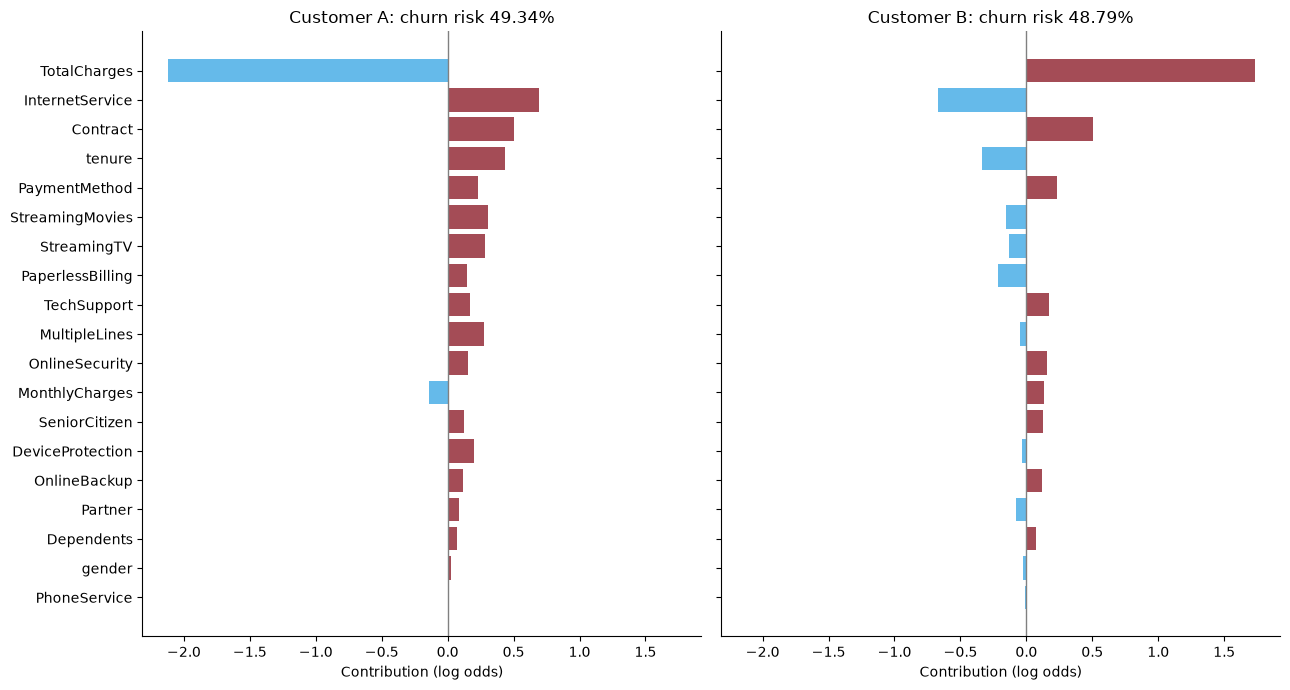

In [13]:
# Keep every signed contribution visible: the bars together add to the displayed score.
case_parts = grouped_parts.loc[list(case_indices.values())].copy()
# Label the display rows A and B while preserving the original explanation arrays.
case_parts.index = list(case_indices)
# Show every contribution so the plotted totals can be checked without hidden remainder terms.
display(case_parts.T)
# Use one order based on both customers' magnitudes so matching features line up across panels.
order = case_parts.abs().mean().sort_values().index
# Share axes so equal bar lengths represent equal log-odds changes for A and B.
fig, axes = plt.subplots(1, 2, figsize=(13, 7), sharex=True, sharey=True)
# Draw each customer on a separate panel using the same reference and feature order.
for ax, (label, index) in zip(axes, case_indices.items()):
    # Select this customer's signed contributions in the common plotting order.
    parts = grouped_parts.loc[index, order]
    # Build colors from contribution direction rather than from feature importance rank.
    colors = []
    # Inspect the sign of each feature's push on this individual score.
    for value in parts:
        # Use red for upward pushes and blue for downward or zero pushes.
        colors.append('#a44c56' if value > 0 else '#65baea')
    # Plot all raw-field contributions with their signs intact.
    ax.barh(order, parts, color=colors)
    # Mark the no-contribution line so left and right have a common interpretation.
    ax.axvline(0, color='grey', linewidth=1)
    # Convert only the complete additive score to probability for the panel title.
    p = float(expit(base_score + parts.sum()))
    # State the individual probability and the different units used by the bars.
    ax.set(title=f'Customer {label}: churn risk {p:.2%}', xlabel='Contribution (log odds)')
# Leave enough room for all field names and both panel labels.
plt.tight_layout()
# Render the two local explanations together for direct comparison.
plt.show()

Read A and B against the same base and zero line. Class risks are about **49.34%**
and **48.79%**, both above the fixed 20% offer cutoff. A's total charges contribute
about **−2.12 log odds**, while B's contribute about **+1.73**. Contract pushes both
up; internet service pushes A up and B down. Similar total risk need not mean similar
reasons. Notice that the joint original-plus-log tenure contribution for A is positive:
do not substitute the intuition that longer tenure must always lower risk.

The bars explain the fitted model. Correlated tenure and charges, raw-plus-log terms,
regularization, and the background affect credit. They do not prove that changing
these fields changes churn or that a discount is the best response. For A, ask whether
the bundle still fits; for B, check onboarding and early bills. Verify those hypotheses
with the customer and test interventions independently.

### Optional comparison: TreeSHAP on the same customer
**Question:** What explains XGBoost's score for customer A? XGBoost computes TreeSHAP
with `pred_contribs=True`; the last column is its own base value. This example uses
the tree-path-dependent default, based on training path information, rather than our
explicit fitting-mean interventional background. Its base and attributions need not
match those of Logistic Regression. Both the **model** and the **explanation game** change.

In [14]:
# Session 4's raw-input XGBoost recipe is a comparison, not a new selection.
tree = build_model(logs=False)
# Replace only the classifier, keeping the raw-input preprocessing and classroom settings.
tree.set_params(model=xgb.XGBClassifier(
    n_estimators=100, learning_rate=.1, max_depth=2,
    tree_method='hist', eval_metric='logloss', random_state=42, n_jobs=1
))
# Learn tree splits and preparation from fitting rows, never validation customers.
tree.fit(X_fit, y_fit)
# Score the same validation customers as the Logistic finalist without refitting.
tree_probabilities = tree.predict_proba(X_valid)[:, 1]
# Measure validation ranking before interpreting the tree explanation.
tree_ap = average_precision_score(y_valid, tree_probabilities)
# Expose the computed tree score for comparison with the class evidence.
print(f"XGBoost validation AP: {tree_ap:.6f}")

XGBoost validation AP: 0.678846


In [15]:
# Use XGBoost's own fitted encoder mapping; it has no added log columns.
tree_groups = encoded_groups(tree)
# Keep the same validation customer when changing the explanation model.
index_a = case_indices['A']
# Apply the fitted tree preparation and wrap the resulting row in XGBoost's matrix format.
tree_row = xgb.DMatrix(tree[:-1].transform(X_valid.loc[[index_a]]))
# Access the underlying trained ensemble that exposes contribution predictions.
booster = tree.named_steps['model'].get_booster()
# Request one TreeSHAP value per encoded input plus a final base-value column.
tree_parts = booster.predict(tree_row, pred_contribs=True)[0]
# Request the ensemble's raw log-odds score before the logistic transformation.
tree_score = float(booster.predict(tree_row, output_margin=True)[0])
# Check that all contributions, including the last base term, reconstruct that score.
np.testing.assert_allclose(tree_parts.sum(), tree_score, atol=1e-5)
# Recover the actual churn probability through the complete fitted tree Pipeline.
tree_probability = float(tree.predict_proba(X_valid.loc[[index_a]])[0, 1])
# Verify that TreeSHAP explains the score behind this probability, not a different output.
np.testing.assert_allclose(expit(tree_score), tree_probability, atol=1e-6)
# Collect signed tree contributions grouped by the original field names.
tree_raw_parts = {}
# Aggregate one-hot terms so the explanation can be read alongside raw customer data.
for name in X.columns:
    # Exclude the base column before selecting and summing a field's encoded contributions.
    tree_raw_parts[name] = tree_parts[:-1][tree_groups == name].sum()
# Show downward and upward pushes in their actual log-odds units.
display(pd.Series(tree_raw_parts, name='TreeSHAP contribution (log odds)').sort_values())
# Expose the tree's own reference and reconstructed total for the arithmetic check.
print(f"Tree base {tree_parts[-1]:.4f} + contributions = {tree_score:.4f}")
# Report the probability explained by these tree contributions for customer A.
print(f"XGBoost risk for A: {tree_probability:.2%}")

tenure             -0.7688
TotalCharges       -0.1455
OnlineBackup       -0.0214
PhoneService       -0.0091
gender              0.0000
DeviceProtection    0.0069
Partner             0.0076
StreamingTV         0.0175
Dependents          0.0237
SeniorCitizen       0.0474
StreamingMovies     0.0558
PaperlessBilling    0.0590
TechSupport         0.1163
MultipleLines       0.1343
OnlineSecurity      0.1423
PaymentMethod       0.1821
InternetService     0.2575
MonthlyCharges      0.3468
Contract            0.4555
Name: TreeSHAP contribution (log odds), dtype: float32

Tree base -1.0417 + contributions = -0.1336
XGBoost risk for A: 46.66%


Class XGBoost risk for A is about **46.66%**. Its tenure contribution is negative,
unlike the Logistic finalist. Inspect each complete score before telling a customer
what the model used. A SHAP result is tied to a particular fitted model, reference and
missing-feature convention; neither agreement nor disagreement establishes causality.

## From one prediction to a global SHAP view
**Question:** Which inputs tend to make the largest pushes across validation customers?
Average the **absolute grouped contributions** to rank magnitude. Keep their signs
visible in the dot plot. This measures score attribution, unlike permutation's loss
of AP. Large positive and negative contributions can cancel in a signed average.

,Mean absolute contribution (log odds)
TotalCharges,1.1256
InternetService,0.6098
Contract,0.5487
tenure,0.2633
StreamingMovies,0.2373
MultipleLines,0.2371
StreamingTV,0.2192
PaperlessBilling,0.1744
TechSupport,0.1667
PaymentMethod,0.1544


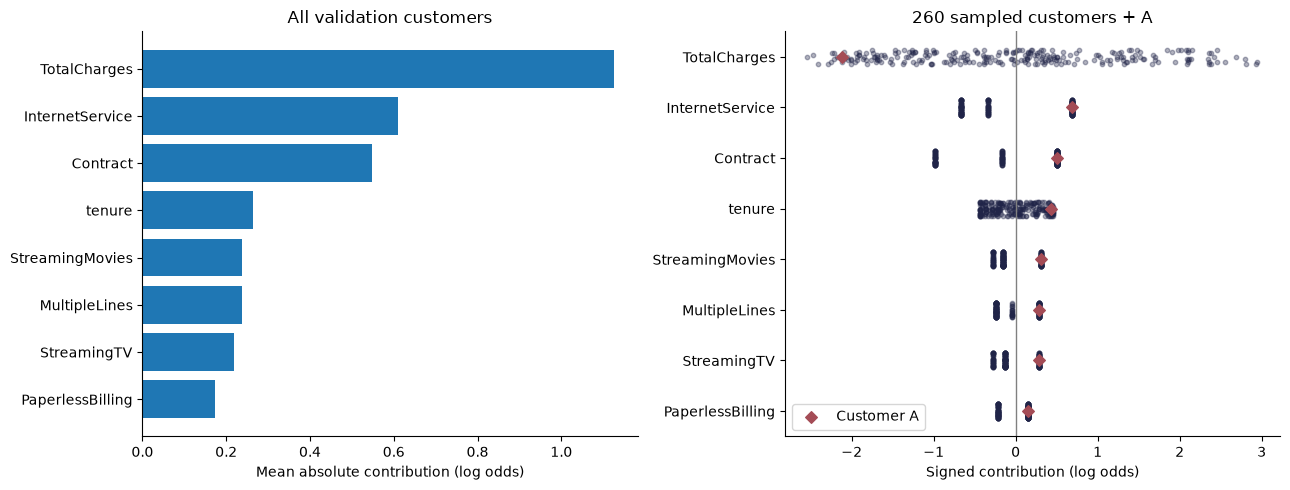

In [16]:
# Average absolute raw-field pushes across customers, then rank by magnitude rather than direction.
global_shap = grouped_parts.abs().mean().sort_values(ascending=False)
# Show the population summary with units; these values are neither AP losses nor probabilities.
display(global_shap.to_frame('Mean absolute contribution (log odds)'))

# Match the lesson: 260 dots for display, means computed on all 1,691 validation rows.
rng = np.random.default_rng(7)
# Select distinct customers for a readable dot plot without changing the all-customer averages.
sample_positions = rng.choice(len(X_valid), size=260, replace=False)
# Use the same top eight features in both panels, with the largest at the top.
top_features = global_shap.head(8).index[::-1]
# Place the magnitude summary beside the distribution of signed individual pushes.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
# Draw averages computed from all 1,691 validation customers.
axes[0].barh(top_features, global_shap.loc[top_features])
# Label the summary measure and the population it actually uses.
axes[0].set(xlabel='Mean absolute contribution (log odds)', title='All validation customers')
# Reserve one horizontal row for each raw field in the signed contribution plot.
for row, name in enumerate(top_features):
    # Select this feature's contributions for the sampled validation customers.
    values = grouped_parts[name].iloc[sample_positions].to_numpy()
    # Spread overlapping dots vertically for readability; jitter does not change their contributions.
    jitter = (sample_positions % 9 - 4) * .035
    # Draw each sampled customer at their signed log-odds contribution.
    axes[1].scatter(values, row + jitter, alpha=.35, s=10, color='#202448')
    # A highlighted diamond links the population plot to the individual explanation.
    axes[1].scatter(grouped_parts.loc[index_a, name], row, marker='D',
                    color='#a44c56', s=35, label='Customer A' if row == 0 else None)
# Align dot rows with the same field names as the magnitude summary.
axes[1].set_yticks(range(len(top_features)), top_features)
# Separate risk-lowering contributions on the left from risk-raising contributions on the right.
axes[1].axvline(0, color='grey', linewidth=1)
# Make the display sample distinct from the population used to calculate the means.
axes[1].set(xlabel='Signed contribution (log odds)', title='260 sampled customers + A')
# Identify the highlighted diamond so students can connect it to A's local explanation.
axes[1].legend()
# Prevent the two panels' feature labels and axes from overlapping.
plt.tight_layout()
# Display the global magnitude and signed distribution together.
plt.show()

Each dot is one customer's contribution for the row's feature. Left lowers the score;
right raises it. The bar length summarizes distances from zero, computed over **all**
validation customers. A feature that is globally large may push a given customer down.
These are log-odds contributions, not AP drops or causal effects. Grouping occurs
**before** taking absolute values, so opposing raw/log terms within one input can cancel.

## Optional syllabus bridge: partial dependence and individual curves
The syllabus includes PDPs; the final Session 7 v3 slides concentrate on importance,
SHAP and audiences. This optional exercise uses the tenure grid from its embedded
experiment without changing the main lesson order.

**Question:** How does the fitted model's predicted risk respond if we set tenure
to the same value for every validation customer, keeping their other raw fields fixed?
The average is a partial dependence plot (PDP). Two individual conditional expectation
(ICE) curves show how the **same** intervention on the model input differs for A and B.
This is a sensitivity calculation, not an estimated effect of retaining a customer longer.

In [17]:
# Collect one average response, two individual responses and a support count per tenure value.
pdp_rows = []
# Step through the lesson's grid from 0 to 72 months, including both endpoints.
for months in range(0, 73, 3):
    # Set all tenures to this value while leaving each customer's other raw fields fixed.
    changed = X_valid.assign(tenure=months)
    # Let the fitted Pipeline recompute log tenure and score every altered row without refitting.
    changed_probabilities = finalist.predict_proba(changed)[:, 1]
    # Average altered risks for PDP and count observed rows nearby for marginal support only.
    row = {'Months': months, 'PDP': changed_probabilities.mean(),
           'Observed rows within 2 months': int((X_valid['tenure'] - months).abs().le(2).sum())}
    # Extract A and B from the same altered population to build their individual ICE curves.
    for label, index in case_indices.items():
        # Translate the stored customer index into a position in the probability array.
        position = X_valid.index.get_loc(index)
        # Keep this customer's altered risk rather than substituting the population average.
        row[label] = changed_probabilities[position]
    # Save the complete response and support information before moving to the next tenure.
    pdp_rows.append(row)
# Label the grid results so their calculations can be inspected independently of the plot.
pdp = pd.DataFrame(pdp_rows)
# Show the actual averages, individual curves and support counts before interpreting them.
display(pdp)

,Months,PDP,Observed rows within 2 months,A,B
0,0,0.2206,196,0.2801,0.4519
1,3,0.2325,308,0.3014,0.4776
2,6,0.2394,162,0.3140,0.4924
3,9,0.2452,144,0.3246,0.5045
4,12,0.2504,146,0.3342,0.5154
5,15,0.2554,125,0.3433,0.5256
6,18,0.2601,97,0.3521,0.5352
7,21,0.2647,77,0.3607,0.5445
8,24,0.2693,88,0.3691,0.5535
9,27,0.2737,102,0.3775,0.5623


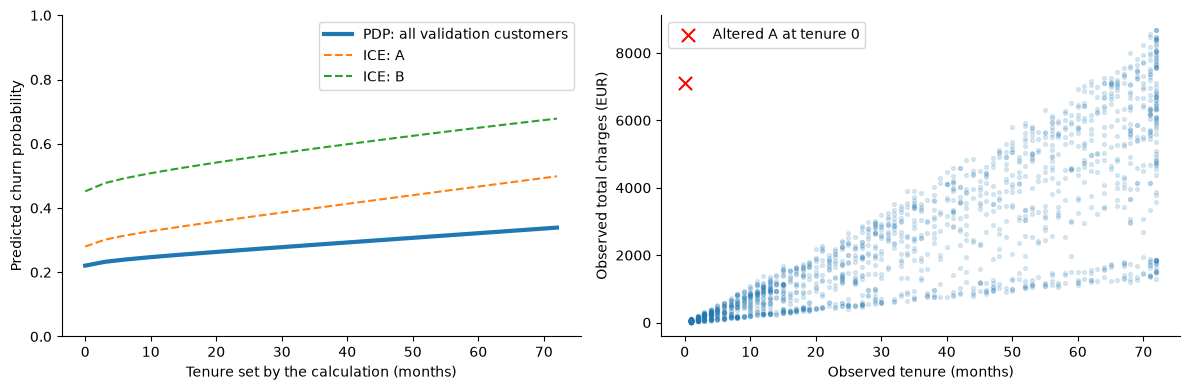

In [18]:
# Put the sensitivity curves beside observed data to reveal unrealistic altered combinations.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# Use a solid line for the average response of the fitted model to altered tenure.
axes[0].plot(pdp['Months'], pdp['PDP'], label='PDP: all validation customers', linewidth=3)
# Add both selected customers so the average cannot hide their different responses.
for label in case_indices:
    # Use dashed lines for individual altered-input predictions, not observed churn frequencies.
    axes[0].plot(pdp['Months'], pdp[label], '--', label=f'ICE: {label}')
# State which input was set and keep the complete zero-to-one probability scale.
axes[0].set(xlabel='Tenure set by the calculation (months)',
            ylabel='Predicted churn probability', ylim=(0, 1))
# Distinguish the population average from the two individual curves.
axes[0].legend()
# Show the real joint tenure/charge support that the sensitivity calculation can leave.
axes[1].scatter(X_valid['tenure'], X_valid['TotalCharges'], s=8, alpha=.15)
# Mark the artificial A profile with zero tenure but its original accumulated bill.
axes[1].scatter([0], [case_inputs.loc['A', 'TotalCharges']], marker='x',
                color='red', s=90, label='Altered A at tenure 0')
# Keep observed data units explicit when checking whether a constructed profile is plausible.
axes[1].set(xlabel='Observed tenure (months)', ylabel='Observed total charges (EUR)')
# Identify the red cross as an altered profile rather than a real observed customer.
axes[1].legend()
# Keep the probability and support panels readable with their separate axis labels.
plt.tight_layout()
# Display response and support together before drawing any interpretation.
plt.show()

Here the average risk rises from about 22% to 34% as tenure increases while charges
stay fixed. Read that model response and each customer separately; it does not establish
that keeping a real customer longer increases churn. At tenure zero, A still has over
EUR 7,100 in accumulated charges: the altered profile is poorly supported. The Pipeline
recomputes log tenure consistently but cannot make that raw billing combination plausible.
The support count near each tenure checks only **marginal** support, not support of
the whole altered profile. Correlation can make PDP and ICE rely on unrealistic combinations;
neither plot tells us what would happen if an actual customer stayed another year.
See [scikit-learn's PDP/ICE guide](https://scikit-learn.org/stable/modules/partial_dependence.html).

## Explain the decision to the person who needs it
The lesson then asks what a person can understand and challenge. Its credit example
refers to the [CJEU's C-203/22 judgment](https://eur-lex.europa.eu/legal-content/EN/TXT/?uri=celex%3A62022CJ0203):
an intelligible explanation must let the person understand and challenge the automated
decision. A technical attribution plot alone does not provide the whole decision record.
In the lesson's hypothetical credit comparison, AUC 0.87 with unstable reasons and no
replay process competes with AUC 0.84 and verified reasons plus review. The metric alone
does not settle whether either workflow is ready for use.

For our Telco customer, use the actual model inputs and policy rather than importing
the credit example's reasons. Adapt the explanation to its audience:

| Audience | What they need from the evidence |
| --- | --- |
| Customer A | The model estimated about 49% risk. Contract, internet service and other recorded fields pushed up its score, while accumulated charges pushed down. Verify the bill and service information and provide a route to correct it and ask for review. |
| Business owner / CFO | Explain why the policy flags A at 0.20, how many people it contacts, and whether incremental retention and margin justify discounts and capacity. SHAP does not measure the offer's effect; Session 6's gain remains uncertain. |
| Reviewer / regulator | Trace the supplied data, fitted model and explanation settings, policy version, threshold, action and any human review. Recompute the result and investigate disputed inputs. Check which safeguards apply to the actual decision. |

The class explanation is not a claim that every retention offer has the same legal
status as an automated credit refusal. Its practical question is whether the person
can identify the information that shaped the action and have it checked.

**Exercise:** Write three short explanations for B. Include one model observation,
one fact to verify and one uncertainty. Then decide what you would require before
approving a pilot: predictive quality by group, stable reasons under plausible
explanation choices, a replay/review process, or more evidence. State why.

**Takeaway:** Permutation measures loss of global predictive performance; local SHAP
allocates a prediction relative to a reference; global SHAP aggregates those allocations.
An action additionally requires a policy and evidence about its consequences. Notebook
14 carries that distinction into a first local service.

Source: local Session 7 v3 slides and embedded code/evidence, with the optional PDP
bridge from the syllabus. These instructor files are not needed at runtime. TreeSHAP
reference: [XGBoost prediction](https://xgboost.readthedocs.io/en/stable/prediction.html).